
# The Thomson Problem: Energy Minimization of Charges on a Sphere

## Research Question

How does the minimum-energy configuration of identical repelling charges on a sphere change as the number of particles increases?

## Objective

The goal of this project is to use numerical optimization to determine the equilibrium configurations of identical electric charges constrained to the surface of a sphere.

We will:
1. Generate random initial particle configurations.
2. Calculate the total electrostatic potential energy.
3. Minimize the energy using numerical optimization.
4. Visualize the configurations before and after optimization.
5. Investigate how the minimum energy depends on the number of particles.

## Physical Background

The Thomson Problem asks how identical point charges should be arranged on the surface of a sphere to minimize their total electrostatic potential energy.

Because the charges repel one another, the equilibrium configuration corresponds to a minimum of the total Coulomb energy.

For N identical charges, the energy is

$$
E = \sum_{i<j} \frac{kq^2}{|\mathbf{r}_i-\mathbf{r}_j|}
$$

where:
- $N$ is the number of charges,
- $q$ is the charge of each particle,
- $k$ is Coulomb's constant,
- $\mathbf{r}_i$ is the position vector of particle $i$.

We use dimensionless units with $kq^2=1$ and a sphere of radius $R=1$.

The optimization problem is

$$
\min_{\mathbf{r}_1,\ldots,\mathbf{r}_N} E
\qquad
\text{subject to } |\mathbf{r}_i|=1.
$$



## Comparison of Optimization Algorithms

### Research Question
Which optimization method most efficiently finds the minimum-energy configuration of charges on a sphere?

We compare three methods:
- BFGS
- L-BFGS-B
- SLSQP

To ensure a fair comparison, all methods start from the same initial particle configurations.

We evaluate:
1. Final electrostatic energy
2. Computational time
3. Number of iterations
4. Convergence behavior

Particle positions are parameterized using spherical coordinates to keep all charges on the unit sphere.


In [1]:

import numpy as np
import matplotlib.pyplot as plt

from scipy.optimize import minimize

np.random.seed(42)

N = 8  # Number of charges
R = 1.0  # Radius of the sphere

print(f"Number of charges: {N}")
print(f"Sphere radius: {R}")


Number of charges: 8
Sphere radius: 1.0


In [2]:

def generate_random_points(N, R=1.0):
    points = np.random.normal(size=(N, 3))

    # Normalize each vector to lie on the sphere
    points /= np.linalg.norm(points, axis=1, keepdims=True)

    return R * points

initial_positions = generate_random_points(N, R)

print("Initial positions:")
print(initial_positions)


Initial positions:
[[ 0.60000205 -0.1670153   0.78237039]
 [ 0.97717133 -0.15023209 -0.15022156]
 [ 0.86889694  0.42224942 -0.25830898]
 [ 0.63675162 -0.5438697  -0.54658314]
 [ 0.09351637 -0.73946664 -0.66666616]
 [-0.46845169 -0.84380753  0.26180501]
 [-0.40741778 -0.63368104  0.65761623]
 [-0.15634329  0.04676125 -0.98659524]]


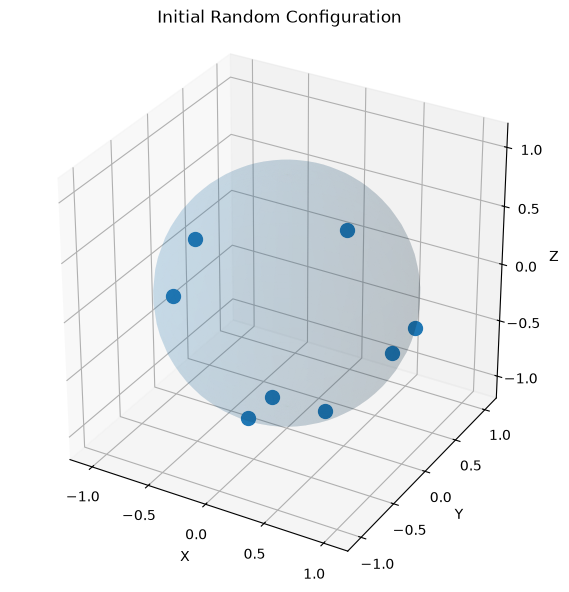

In [3]:

def plot_configuration(points, title):
    fig = plt.figure(figsize=(7, 7))
    ax = fig.add_subplot(111, projection="3d")

    # Draw the sphere
    u = np.linspace(0, 2*np.pi, 50)
    v = np.linspace(0, np.pi, 30)

    x = R * np.outer(np.cos(u), np.sin(v))
    y = R * np.outer(np.sin(u), np.sin(v))
    z = R * np.outer(np.ones_like(u), np.cos(v))

    ax.plot_surface(x, y, z, alpha=0.12)

    # Draw the charges
    ax.scatter(
        points[:, 0],
        points[:, 1],
        points[:, 2],
        s=100,
        depthshade=False
    )

    ax.set(
        xlim=(-1.2*R, 1.2*R),
        ylim=(-1.2*R, 1.2*R),
        zlim=(-1.2*R, 1.2*R),
        xlabel="X",
        ylabel="Y",
        zlabel="Z",
        title=title
    )

    ax.set_box_aspect((1, 1, 1))
    plt.show()

plot_configuration(initial_positions, "Initial Random Configuration")


In [5]:

def coulomb_energy(points):
    energy = 0.0
    N = len(points)

    for i in range(N):
        for j in range(i + 1, N):
            distance = np.linalg.norm(points[i] - points[j])

            if distance < 1e-12:
                return 1e12

            energy += 1.0 / distance

    return energy


In [6]:

import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# Convert spherical angles to Cartesian coordinates
def angles_to_points(angles):
    angles = angles.reshape(-1, 2)
    theta = angles[:, 0]
    phi = angles[:, 1]

    return np.column_stack([
        np.sin(theta) * np.cos(phi),
        np.sin(theta) * np.sin(phi),
        np.cos(theta)
    ])

def energy_from_angles(angles):
    return coulomb_energy(angles_to_points(angles))

# Use identical initial conditions
rng = np.random.default_rng(42)
initial_angles = np.column_stack([
    np.arccos(rng.uniform(-1, 1, N)),
    rng.uniform(0, 2*np.pi, N)
]).flatten()

methods = ["BFGS", "L-BFGS-B", "SLSQP"]
results = {}

for method in methods:
    history = [energy_from_angles(initial_angles)]

    def callback(xk):
        history.append(energy_from_angles(xk))

    start = time.perf_counter()

    result = minimize(
        energy_from_angles,
        initial_angles.copy(),
        method=method,
        callback=callback,
        options={"maxiter": 1000, "ftol": 1e-10}
        if method != "BFGS"
        else {"maxiter": 1000, "gtol": 1e-7}
    )

    elapsed = time.perf_counter() - start

    results[method] = {
        "energy": result.fun,
        "time": elapsed,
        "iterations": result.nit,
        "history": history,
        "success": result.success,
        "positions": angles_to_points(result.x)
    }

    print(
        f"{method}: Energy={result.fun:.6f}, "
        f"Time={elapsed:.4f}s, "
        f"Iterations={result.nit}, "
        f"Success={result.success}"
    )


BFGS: Energy=19.675288, Time=0.0401s, Iterations=38, Success=False
L-BFGS-B: Energy=19.675288, Time=0.0343s, Iterations=30, Success=True
SLSQP: Energy=19.675288, Time=0.0285s, Iterations=31, Success=True


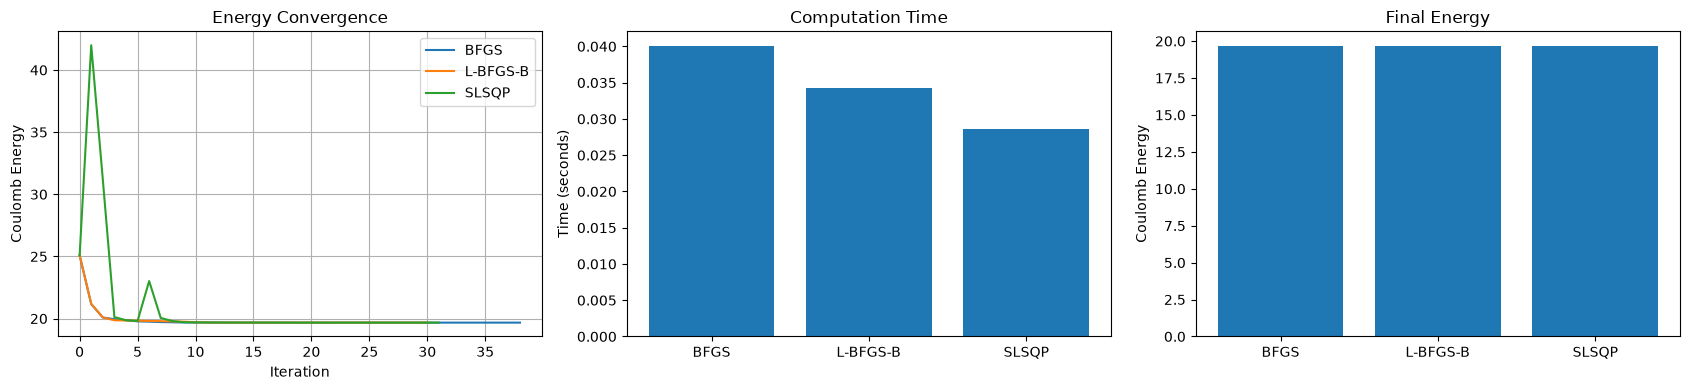

In [7]:

fig, axes = plt.subplots(1, 3, figsize=(17, 4))

# Plot 1: Convergence
for method in methods:
    history = results[method]["history"]
    axes[0].plot(
        range(len(history)),
        history,
        label=method
    )

axes[0].set_title("Energy Convergence")
axes[0].set_xlabel("Iteration")
axes[0].set_ylabel("Coulomb Energy")
axes[0].legend()
axes[0].grid(True)

# Plot 2: Computation time
axes[1].bar(
    methods,
    [results[m]["time"] for m in methods]
)
axes[1].set_title("Computation Time")
axes[1].set_ylabel("Time (seconds)")

# Plot 3: Final energy
axes[2].bar(
    methods,
    [results[m]["energy"] for m in methods]
)
axes[2].set_title("Final Energy")
axes[2].set_ylabel("Coulomb Energy")
axes[2].ticklabel_format(
    axis="y", style="plain", useOffset=False
)

plt.tight_layout()
plt.show()



### Results

For N = 8 charges, all three optimization algorithms reached approximately the same minimum Coulomb energy:

$$
E_{\min} \approx 19.675288
$$

This agrees with the known minimum-energy configuration of the Thomson Problem for eight charges.

**Key observations:**

- **BFGS:** Reached the expected energy in 38 iterations, but reported unsuccessful termination.
- **L-BFGS-B:** Reached the expected energy in 30 iterations, requiring the fewest iterations.
- **SLSQP:** Reached the expected energy in 31 iterations and had the shortest computation time in this run.

The convergence plot shows that all three algorithms approach the same energy minimum, although their convergence paths differ.

**Preliminary conclusion:**

SLSQP was the fastest algorithm in this particular run, while L-BFGS-B required the fewest iterations.

However, a single optimization run is not sufficient to identify the most reliable algorithm. Further experiments with multiple random initial configurations are necessary.


In [10]:

import pandas as pd

n_trials = 10
comparison_data = []
rng = np.random.default_rng(2026)

for trial in range(n_trials):

    initial_angles = np.column_stack([
        np.arccos(rng.uniform(-1, 1, N)),
        rng.uniform(0, 2*np.pi, N)
    ]).flatten()

    for method in methods:

        start = time.perf_counter()

        result = minimize(
            energy_from_angles,
            initial_angles.copy(),
            method=method,
            options=(
                {"maxiter": 1000, "gtol": 1e-7}
                if method == "BFGS"
                else {"maxiter": 1000, "ftol": 1e-10}
            )
        )

        elapsed = time.perf_counter() - start

        comparison_data.append({
            "Trial": trial + 1,
            "Method": method,
            "Energy": result.fun,
            "Time": elapsed,
            "Iterations": result.nit,
            "Success": result.success,
            "Near Known Minimum": abs(result.fun - 19.675288) < 1e-4
        })

df = pd.DataFrame(comparison_data)

summary = df.groupby("Method").agg(
    Mean_Energy=("Energy", "mean"),
    Mean_Time=("Time", "mean"),
    Mean_Iterations=("Iterations", "mean"),
    Solver_Success_Rate=("Success", "mean"),
    Minimum_Found_Rate=("Near Known Minimum", "mean")
)

print(summary.round(6))


          Mean_Energy  Mean_Time  Mean_Iterations  Solver_Success_Rate  \
Method                                                                   
BFGS        19.675288   0.022083             39.0                  0.0   
L-BFGS-B    19.675288   0.015288             30.4                  1.0   
SLSQP       19.675288   0.015054             33.0                  1.0   

          Minimum_Found_Rate  
Method                        
BFGS                     1.0  
L-BFGS-B                 1.0  
SLSQP                    1.0  


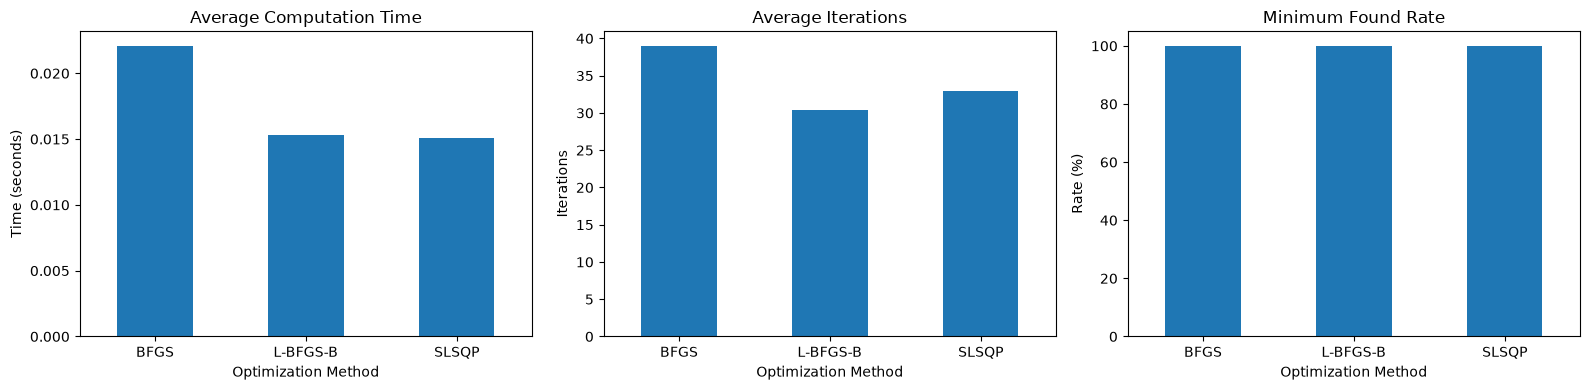

In [11]:

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

summary["Mean_Time"].plot(
    kind="bar",
    ax=axes[0],
    title="Average Computation Time"
)
axes[0].set_ylabel("Time (seconds)")

summary["Mean_Iterations"].plot(
    kind="bar",
    ax=axes[1],
    title="Average Iterations"
)
axes[1].set_ylabel("Iterations")

(summary["Minimum_Found_Rate"] * 100).plot(
    kind="bar",
    ax=axes[2],
    title="Minimum Found Rate"
)
axes[2].set_ylabel("Rate (%)")
axes[2].set_ylim(0, 105)

for ax in axes:
    ax.set_xlabel("Optimization Method")
    ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()



## Effect of the Number of Charges

We investigate how the minimum electrostatic energy changes as the number of charges increases.

We consider N = 4, 6, 8, 12, and 20.

For each system, we use numerical optimization to find a low-energy configuration and compare the resulting energies.


In [12]:

particle_numbers = [4, 6, 8, 12, 20]
minimum_energies = []

rng = np.random.default_rng(123)

for n in particle_numbers:

    initial = rng.normal(size=(n, 3))
    initial /= np.linalg.norm(initial, axis=1, keepdims=True)

    def objective_n(x):
        return coulomb_energy(x.reshape(n, 3))

    def constraints_n(x):
        points = x.reshape(n, 3)
        return np.sum(points**2, axis=1) - 1.0

    result_n = minimize(
        objective_n,
        initial.flatten(),
        method="SLSQP",
        constraints={
            "type": "eq",
            "fun": constraints_n
        },
        options={"maxiter": 2000, "ftol": 1e-10}
    )

    energy = result_n.fun
    minimum_energies.append(energy)

    print(
        f"N={n}, Energy={energy:.6f}, "
        f"Success={result_n.success}"
    )


N=4, Energy=3.674235, Success=True
N=6, Energy=9.985281, Success=True
N=8, Energy=19.675288, Success=True
N=12, Energy=49.165253, Success=True
N=20, Energy=150.881568, Success=True


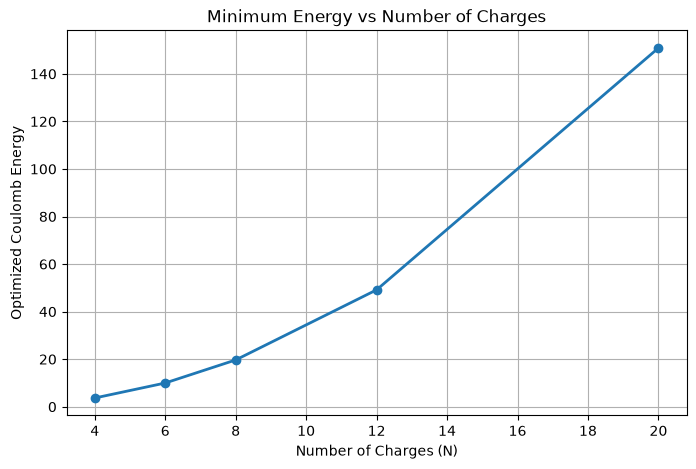

In [13]:

plt.figure(figsize=(8, 5))

plt.plot(
    particle_numbers,
    minimum_energies,
    marker="o",
    linewidth=2
)

plt.xlabel("Number of Charges (N)")
plt.ylabel("Optimized Coulomb Energy")
plt.title("Minimum Energy vs Number of Charges")
plt.grid(True)

plt.show()


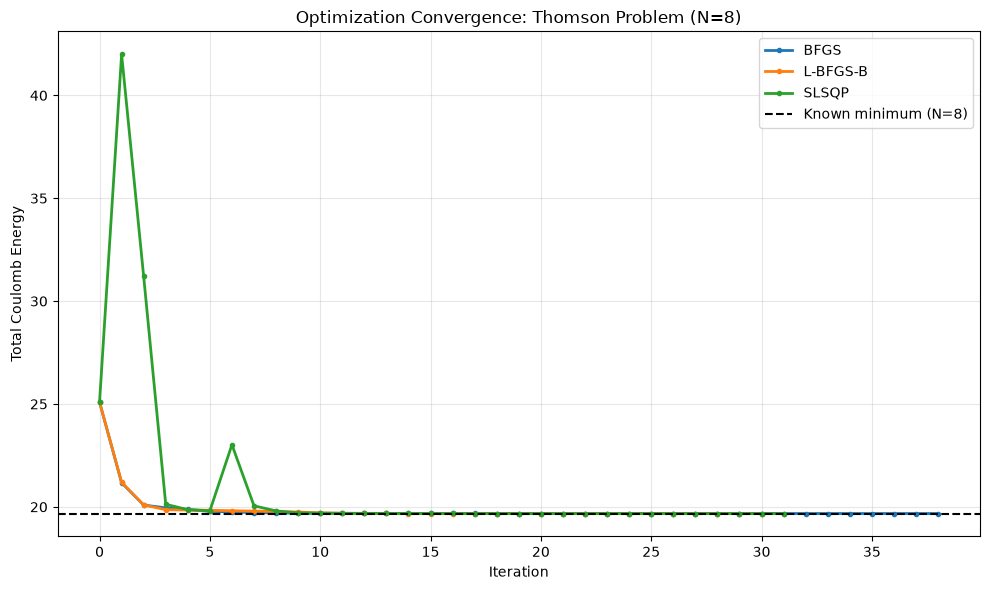

In [14]:

# Optimization Convergence Plot

plt.figure(figsize=(10, 6))

for method in methods:
    history = np.array(results[method]["history"])

    plt.plot(
        range(len(history)),
        history,
        marker="o",
        markersize=3,
        linewidth=2,
        label=method
    )

plt.axhline(
    y=19.675288,
    color="black",
    linestyle="--",
    label="Known minimum (N=8)"
)

plt.xlabel("Iteration")
plt.ylabel("Total Coulomb Energy")
plt.title("Optimization Convergence: Thomson Problem (N=8)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


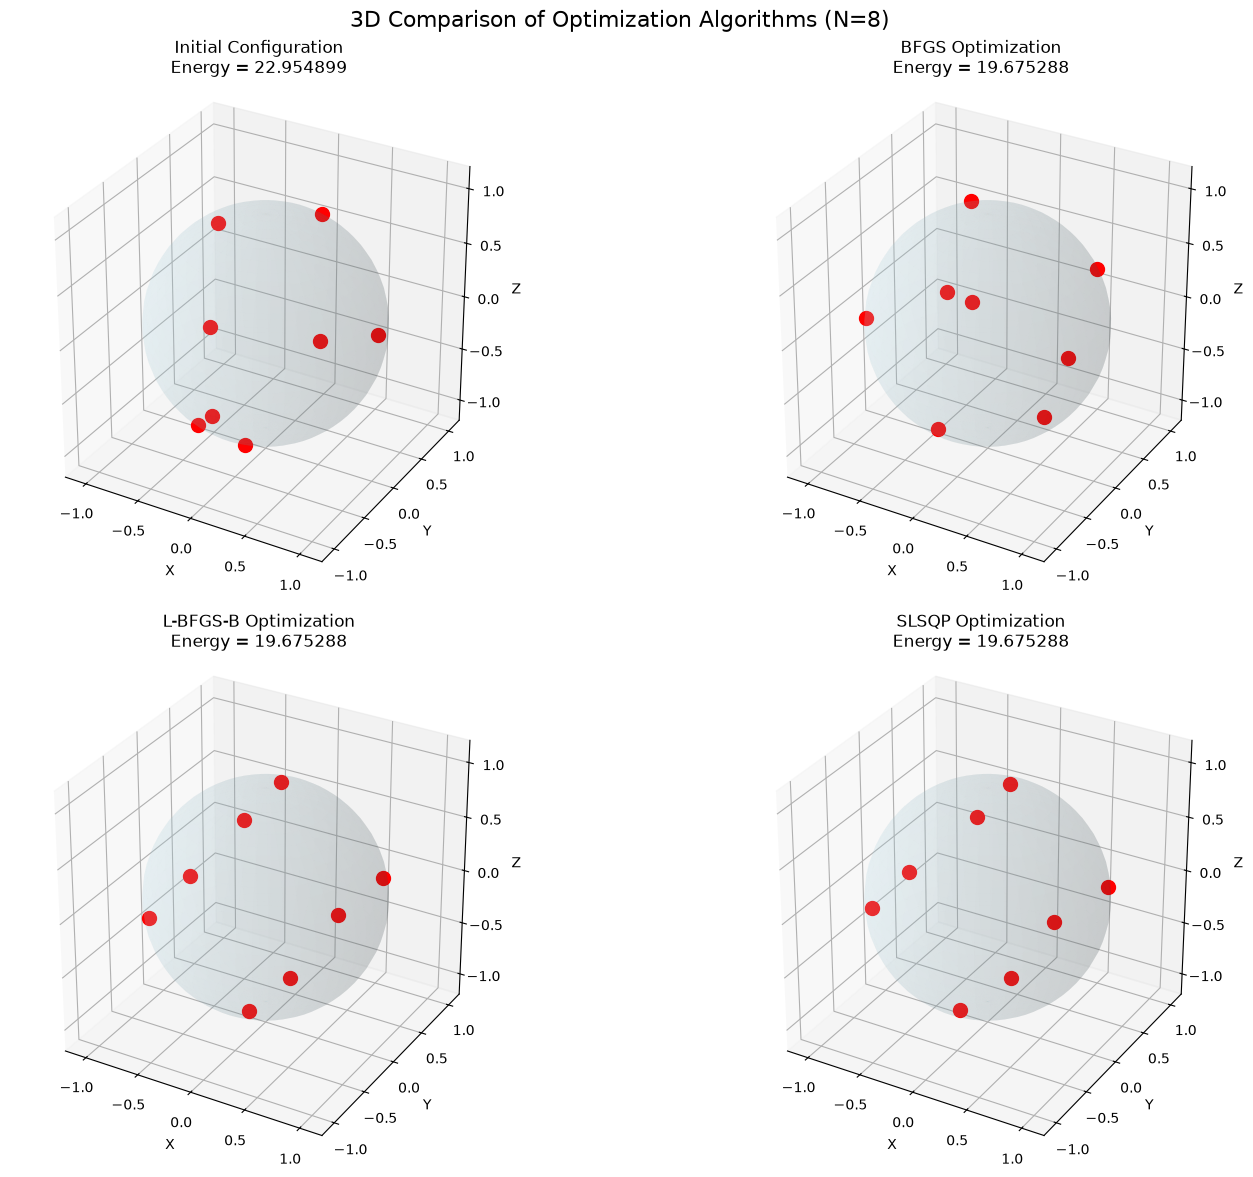

In [15]:

# 3D Optimization Comparison: Thomson Problem

import numpy as np
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(16, 12))

# Sphere coordinates
u = np.linspace(0, 2*np.pi, 50)
v = np.linspace(0, np.pi, 30)

x = np.outer(np.cos(u), np.sin(v))
y = np.outer(np.sin(u), np.sin(v))
z = np.outer(np.ones_like(u), np.cos(v))

# Initial configuration used in algorithm comparison
initial_points = angles_to_points(initial_angles)

configurations = [
    ("Initial Configuration", initial_points),
    ("BFGS Optimization", results["BFGS"]["positions"]),
    ("L-BFGS-B Optimization", results["L-BFGS-B"]["positions"]),
    ("SLSQP Optimization", results["SLSQP"]["positions"])
]

for i, (title, points) in enumerate(configurations):

    ax = fig.add_subplot(2, 2, i + 1, projection="3d")

    # Draw transparent sphere
    ax.plot_surface(
        x, y, z,
        alpha=0.12,
        color="lightblue"
    )

    # Plot charges
    ax.scatter(
        points[:, 0],
        points[:, 1],
        points[:, 2],
        color="red",
        s=100,
        depthshade=False
    )

    # Calculate energy
    energy = coulomb_energy(points)

    ax.set_title(
        f"{title}\nEnergy = {energy:.6f}",
        fontsize=12
    )

    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_zlabel("Z")

    ax.set_xlim(-1.2, 1.2)
    ax.set_ylim(-1.2, 1.2)
    ax.set_zlim(-1.2, 1.2)

    ax.set_box_aspect([1, 1, 1])

plt.suptitle(
    "3D Comparison of Optimization Algorithms (N=8)",
    fontsize=16
)

plt.tight_layout()
plt.show()


In [16]:

%pip install plotly nbformat


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.7/9.7 MB 55.7 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9/9 [nbformat]5/9 [plotly]s]
Note: you may need to restart the kernel to use updated packages.


In [17]:

import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Sphere surface
u = np.linspace(0, 2*np.pi, 50)
v = np.linspace(0, np.pi, 30)

x = np.outer(np.cos(u), np.sin(v))
y = np.outer(np.sin(u), np.sin(v))
z = np.outer(np.ones_like(u), np.cos(v))

# Recover the initial configuration from Step 6
rng_initial = np.random.default_rng(42)
original_angles = np.column_stack([
    np.arccos(rng_initial.uniform(-1, 1, N)),
    rng_initial.uniform(0, 2*np.pi, N)
]).flatten()

initial_points = angles_to_points(original_angles)

configurations = [
    ("Initial", initial_points),
    ("BFGS", results["BFGS"]["positions"]),
    ("L-BFGS-B", results["L-BFGS-B"]["positions"]),
    ("SLSQP", results["SLSQP"]["positions"])
]

fig = make_subplots(
    rows=2,
    cols=2,
    specs=[[{"type": "scene"}, {"type": "scene"}],
           [{"type": "scene"}, {"type": "scene"}]],
    subplot_titles=[
        f"{name} | E = {coulomb_energy(points):.6f}"
        for name, points in configurations
    ]
)

for i, (name, points) in enumerate(configurations):
    row = i // 2 + 1
    col = i % 2 + 1

    fig.add_trace(
        go.Surface(
            x=x, y=y, z=z,
            opacity=0.15,
            colorscale="Blues",
            showscale=False,
            hoverinfo="skip"
        ),
        row=row, col=col
    )

    fig.add_trace(
        go.Scatter3d(
            x=points[:, 0],
            y=points[:, 1],
            z=points[:, 2],
            mode="markers",
            marker=dict(size=7, color="red"),
            name=name,
            text=[f"Charge {j+1}" for j in range(len(points))],
            hovertemplate="%{text}<extra></extra>",
            showlegend=False
        ),
        row=row, col=col
    )

fig.update_layout(
    title="Interactive 3D Thomson Problem: Optimization Comparison",
    height=850,
    margin=dict(l=0, r=0, t=90, b=0)
)

fig.update_scenes(
    aspectmode="cube",
    xaxis=dict(range=[-1.2, 1.2]),
    yaxis=dict(range=[-1.2, 1.2]),
    zaxis=dict(range=[-1.2, 1.2])
)

fig.show()



## Stability Analysis of the Equilibrium Configuration

### Research Question
How stable is the optimized configuration under small random perturbations?

After finding a minimum-energy configuration, we introduce small random displacements to the particle positions.

We then calculate how the total Coulomb energy changes with perturbation strength.

A stable local minimum should have an energy that does not decrease under sufficiently small perturbations.


In [18]:

# Stability Analysis of Optimized Configuration

optimized_points = results["SLSQP"]["positions"]

original_energy = coulomb_energy(optimized_points)

perturbation_strengths = np.linspace(0, 0.3, 25)
mean_energies = []
std_energies = []

rng = np.random.default_rng(123)
n_samples = 100

for strength in perturbation_strengths:
    energies = []

    for _ in range(n_samples):
        noise = rng.normal(size=optimized_points.shape)

        perturbed = optimized_points + strength * noise

        # Keep all charges on the unit sphere
        perturbed /= np.linalg.norm(
            perturbed, axis=1, keepdims=True
        )

        energies.append(coulomb_energy(perturbed))

    mean_energies.append(np.mean(energies))
    std_energies.append(np.std(energies))

print(f"Original optimized energy: {original_energy:.6f}")


Original optimized energy: 19.675288


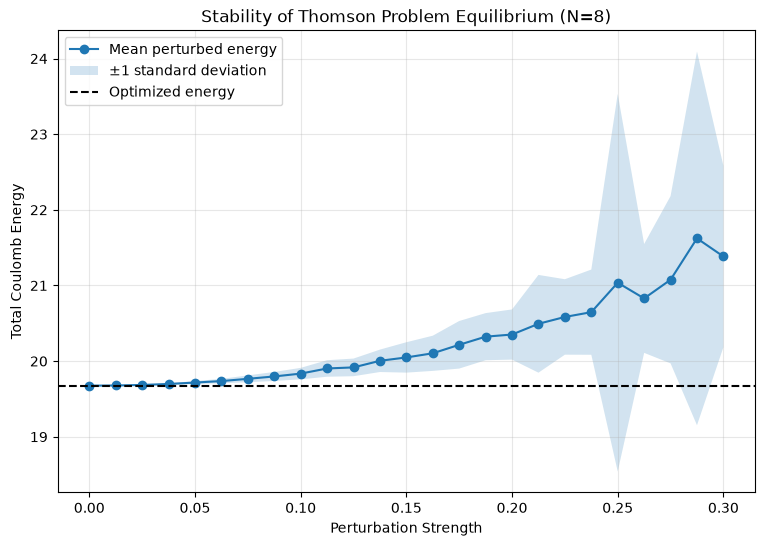

In [19]:

plt.figure(figsize=(9, 6))

mean_energies = np.array(mean_energies)
std_energies = np.array(std_energies)

plt.plot(
    perturbation_strengths,
    mean_energies,
    marker="o",
    label="Mean perturbed energy"
)

plt.fill_between(
    perturbation_strengths,
    mean_energies - std_energies,
    mean_energies + std_energies,
    alpha=0.2,
    label="±1 standard deviation"
)

plt.axhline(
    original_energy,
    linestyle="--",
    color="black",
    label="Optimized energy"
)

plt.xlabel("Perturbation Strength")
plt.ylabel("Total Coulomb Energy")
plt.title("Stability of Thomson Problem Equilibrium (N=8)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


In [20]:

import pandas as pd
import numpy as np

reference_energies = {
    4: 3.674234614,
    6: 9.985281374,
    8: 19.675287861,
    12: 49.165253058,
    20: 150.881568334
}

validation_data = []

for n, computed in zip(particle_numbers, minimum_energies):
    reference = reference_energies[n]
    error = abs(computed - reference)

    validation_data.append({
        "N": n,
        "Computed Energy": computed,
        "Reference Energy": reference,
        "Absolute Error": error
    })

validation_df = pd.DataFrame(validation_data)

print(validation_df.to_string(index=False))


 N  Computed Energy  Reference Energy  Absolute Error
 4         3.674235          3.674235    1.498113e-10
 6         9.985281          9.985281    1.899654e-10
 8        19.675288         19.675288    1.913740e-10
12        49.165253         49.165253    4.032188e-10
20       150.881568        150.881568    5.546497e-10


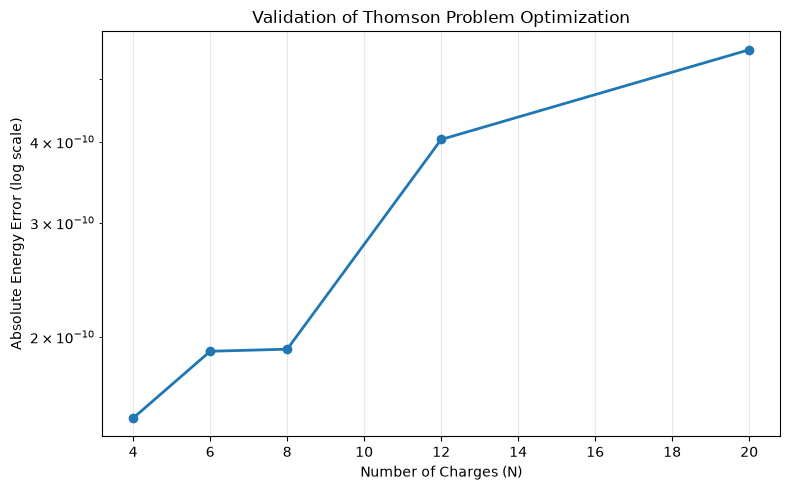

In [21]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.semilogy(
    validation_df["N"],
    np.maximum(validation_df["Absolute Error"], 1e-14),
    marker="o",
    linewidth=2
)

plt.xlabel("Number of Charges (N)")
plt.ylabel("Absolute Energy Error (log scale)")
plt.title("Validation of Thomson Problem Optimization")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()



## 3D Visualization of Equilibrium Configurations

We visualize optimized charge configurations for different numbers of particles: N = 4, 6, 8, 12, and 20.

The goal is to investigate how the spatial arrangement of repelling charges changes with system size.

Each configuration is obtained by minimizing the total Coulomb potential energy on the surface of a unit sphere.


In [23]:

# Calculate and save optimized configurations

import numpy as np
from scipy.optimize import minimize

particle_numbers = [4, 6, 8, 12, 20]
best_configurations = {}
minimum_energies = []

rng = np.random.default_rng(123)

for n in particle_numbers:
    best_energy = np.inf
    best_positions = None

    for trial in range(5):
        initial = rng.normal(size=(n, 3))
        initial /= np.linalg.norm(
            initial, axis=1, keepdims=True
        )

        def objective(x):
            return coulomb_energy(x.reshape(n, 3))

        def constraint(x):
            points = x.reshape(n, 3)
            return np.sum(points**2, axis=1) - 1.0

        result = minimize(
            objective,
            initial.flatten(),
            method="SLSQP",
            constraints={
                "type": "eq",
                "fun": constraint
            },
            options={"maxiter": 2000, "ftol": 1e-10}
        )

        error = np.max(np.abs(constraint(result.x)))

        if error < 1e-6 and result.fun < best_energy:
            best_energy = result.fun
            best_positions = result.x.reshape(n, 3).copy()

    best_configurations[n] = best_positions
    minimum_energies.append(best_energy)

    print(f"N={n}: Energy={best_energy:.6f}")


N=4: Energy=3.674235
N=6: Energy=9.985281
N=8: Energy=19.675288
N=12: Energy=49.165253
N=20: Energy=150.881568


In [25]:

import numpy as np
import plotly.graph_objects as go
from scipy.spatial import ConvexHull

# Select number of charges
N_visual = 12  # Change to 4, 6, 8, 12, or 20

points = best_configurations[N_visual]
energy = coulomb_energy(points)

fig = go.Figure()

# Smooth transparent sphere
u = np.linspace(0, 2*np.pi, 100)
v = np.linspace(0, np.pi, 70)

sx = np.outer(np.cos(u), np.sin(v))
sy = np.outer(np.sin(u), np.sin(v))
sz = np.outer(np.ones_like(u), np.cos(v))

fig.add_trace(go.Surface(
    x=sx, y=sy, z=sz,
    colorscale=[[0, "#10213b"], [1, "#335c91"]],
    opacity=0.22,
    showscale=False,
    hoverinfo="skip",
    lighting=dict(
        ambient=0.45,
        diffuse=0.8,
        specular=0.9,
        roughness=0.15
    ),
    name="Unit sphere"
))

# Geometric edges from convex hull
hull = ConvexHull(points)
edges = set()

for triangle in hull.simplices:
    for i in range(3):
        a = triangle[i]
        b = triangle[(i+1) % 3]
        edges.add(tuple(sorted((a, b))))

edge_x, edge_y, edge_z = [], [], []

for a, b in edges:
    edge_x += [points[a, 0], points[b, 0], None]
    edge_y += [points[a, 1], points[b, 1], None]
    edge_z += [points[a, 2], points[b, 2], None]

fig.add_trace(go.Scatter3d(
    x=edge_x, y=edge_y, z=edge_z,
    mode="lines",
    line=dict(color="#32d5ff", width=5),
    opacity=0.75,
    hoverinfo="skip",
    name="Geometric edges"
))

# Glow effect: larger translucent markers
fig.add_trace(go.Scatter3d(
    x=points[:, 0],
    y=points[:, 1],
    z=points[:, 2],
    mode="markers",
    marker=dict(
        size=18,
        color="#ff477e",
        opacity=0.18
    ),
    hoverinfo="skip",
    showlegend=False
))

# Charges
fig.add_trace(go.Scatter3d(
    x=points[:, 0],
    y=points[:, 1],
    z=points[:, 2],
    mode="markers+text",
    marker=dict(
        size=8,
        color="#ff5688",
        line=dict(color="#ffffff", width=2)
    ),
    text=[str(i+1) for i in range(N_visual)],
    textposition="top center",
    textfont=dict(color="white", size=10),
    hovertemplate=(
        "Charge %{text}<br>"
        "x=%{x:.3f}<br>"
        "y=%{y:.3f}<br>"
        "z=%{z:.3f}<extra></extra>"
    ),
    name="Electric charges"
))

fig.update_layout(
    title=dict(
        text=(
            f"THOMSON PROBLEM | N = {N_visual}"
            f"<br><sup>Optimized Coulomb Energy = {energy:.6f}</sup>"
        ),
        x=0.5,
        font=dict(size=23, color="white")
    ),
    paper_bgcolor="#080f1e",
    font=dict(color="white"),
    scene=dict(
        bgcolor="#080f1e",
        xaxis=dict(visible=False, range=[-1.3, 1.3]),
        yaxis=dict(visible=False, range=[-1.3, 1.3]),
        zaxis=dict(visible=False, range=[-1.3, 1.3]),
        aspectmode="cube",
        camera=dict(eye=dict(x=1.8, y=1.8, z=1.3))
    ),
    showlegend=False,
    height=750,
    margin=dict(l=0, r=0, t=85, b=0)
)

fig.show()



### 3D Visualization of the Optimized Configuration

The interactive 3D plot shows the minimum-energy arrangement of 12 identical charges on a unit sphere.

- **Pink points:** Electric charges.
- **Blue sphere:** Surface on which the charges are constrained.
- **Cyan lines:** Geometric connections between neighboring charges (not physical bonds).

The optimized configuration forms an **icosahedron**, with 12 vertices and 20 triangular faces.

The minimum Coulomb energy is:

$$
E_{\min} \approx 49.165253
$$

This agrees with the known minimum energy for N = 12.

**Conclusion:** Numerical optimization successfully reproduces the expected equilibrium configuration, demonstrating how electrostatic repulsion determines the spatial arrangement of charges.


In [27]:

import numpy as np
import plotly.graph_objects as go
from scipy.optimize import minimize

N_movie = 12
rng = np.random.default_rng(42)

# Random initial configuration
initial = rng.normal(size=(N_movie, 3))
initial /= np.linalg.norm(
    initial, axis=1, keepdims=True
)

# Store optimization trajectory
trajectory = [initial.copy()]

def objective_movie(x):
    points = x.reshape(N_movie, 3)
    return coulomb_energy(points)

def constraint_movie(x):
    points = x.reshape(N_movie, 3)
    return np.sum(points**2, axis=1) - 1

def save_step(xk):
    points = xk.reshape(N_movie, 3).copy()
    points /= np.linalg.norm(
        points, axis=1, keepdims=True
    )
    trajectory.append(points)

result_movie = minimize(
    objective_movie,
    initial.flatten(),
    method="SLSQP",
    constraints={
        "type": "eq",
        "fun": constraint_movie
    },
    callback=save_step,
    options={
        "maxiter": 2000,
        "ftol": 1e-10
    }
)

final_points = result_movie.x.reshape(N_movie, 3)
final_points /= np.linalg.norm(
    final_points, axis=1, keepdims=True
)

trajectory.append(final_points)

energies = [
    coulomb_energy(points)
    for points in trajectory
]

print("Optimization success:", result_movie.success)
print("Number of frames:", len(trajectory))
print("Initial energy:", energies[0])
print("Final energy:", energies[-1])


Optimization success: True
Number of frames: 35
Initial energy: 61.809027869735566
Final energy: 49.1652530576306


In [28]:

import plotly.graph_objects as go

# Sphere surface
u = np.linspace(0, 2*np.pi, 70)
v = np.linspace(0, np.pi, 40)

sx = np.outer(np.cos(u), np.sin(v))
sy = np.outer(np.sin(u), np.sin(v))
sz = np.outer(np.ones_like(u), np.cos(v))

fig = go.Figure()

fig.add_trace(go.Surface(
    x=sx, y=sy, z=sz,
    colorscale=[[0, "#14294a"], [1, "#365b8b"]],
    opacity=0.18,
    showscale=False,
    hoverinfo="skip"
))

fig.add_trace(go.Scatter3d(
    x=trajectory[0][:, 0],
    y=trajectory[0][:, 1],
    z=trajectory[0][:, 2],
    mode="markers",
    marker=dict(
        size=9,
        color="#ff5688",
        line=dict(color="white", width=1)
    ),
    name="Charges"
))

frames = []

for i, points in enumerate(trajectory):
    frames.append(
        go.Frame(
            name=str(i),
            data=[
                go.Scatter3d(
                    x=points[:, 0],
                    y=points[:, 1],
                    z=points[:, 2],
                    mode="markers",
                    marker=dict(
                        size=9,
                        color="#ff5688",
                        line=dict(color="white", width=1)
                    )
                )
            ],
            traces=[1],
            layout=go.Layout(
                title_text=(
                    f"THOMSON PROBLEM | N = {N_movie}"
                    f"<br><sup>Iteration {i} | "
                    f"Energy = {energies[i]:.6f}</sup>"
                )
            )
        )
    )

fig.frames = frames

fig.update_layout(
    title=dict(
        text=f"THOMSON PROBLEM | N = {N_movie}",
        x=0.5
    ),
    paper_bgcolor="#080f1e",
    font=dict(color="white"),
    scene=dict(
        bgcolor="#080f1e",
        xaxis=dict(visible=False, range=[-1.2, 1.2]),
        yaxis=dict(visible=False, range=[-1.2, 1.2]),
        zaxis=dict(visible=False, range=[-1.2, 1.2]),
        aspectmode="cube",
        camera=dict(eye=dict(x=1.5, y=1.5, z=1.2))
    ),
    updatemenus=[dict(
        type="buttons",
        showactive=False,
        buttons=[
            dict(
                label="▶ Play",
                method="animate",
                args=[
                    None,
                    dict(
                        frame=dict(duration=180, redraw=True),
                        transition=dict(duration=0),
                        fromcurrent=True
                    )
                ]
            ),
            dict(
                label="❚❚ Pause",
                method="animate",
                args=[
                    [None],
                    dict(
                        mode="immediate",
                        frame=dict(duration=0, redraw=False),
                        transition=dict(duration=0)
                    )
                ]
            )
        ],
        x=0.05,
        y=0.05
    )],
    height=700,
    margin=dict(l=0, r=0, t=90, b=0)
)

fig.show()


In [29]:

import numpy as np
import plotly.graph_objects as go
from scipy.spatial import ConvexHull

# Select number of charges
N_visual = 20  # Change to 4, 6, 8, 12, or 20

points = best_configurations[N_visual]
energy = coulomb_energy(points)

fig = go.Figure()

# Smooth transparent sphere
u = np.linspace(0, 2*np.pi, 100)
v = np.linspace(0, np.pi, 70)

sx = np.outer(np.cos(u), np.sin(v))
sy = np.outer(np.sin(u), np.sin(v))
sz = np.outer(np.ones_like(u), np.cos(v))

fig.add_trace(go.Surface(
    x=sx, y=sy, z=sz,
    colorscale=[[0, "#10213b"], [1, "#335c91"]],
    opacity=0.22,
    showscale=False,
    hoverinfo="skip",
    lighting=dict(
        ambient=0.45,
        diffuse=0.8,
        specular=0.9,
        roughness=0.15
    ),
    name="Unit sphere"
))

# Geometric edges from convex hull
hull = ConvexHull(points)
edges = set()

for triangle in hull.simplices:
    for i in range(3):
        a = triangle[i]
        b = triangle[(i+1) % 3]
        edges.add(tuple(sorted((a, b))))

edge_x, edge_y, edge_z = [], [], []

for a, b in edges:
    edge_x += [points[a, 0], points[b, 0], None]
    edge_y += [points[a, 1], points[b, 1], None]
    edge_z += [points[a, 2], points[b, 2], None]

fig.add_trace(go.Scatter3d(
    x=edge_x, y=edge_y, z=edge_z,
    mode="lines",
    line=dict(color="#32d5ff", width=5),
    opacity=0.75,
    hoverinfo="skip",
    name="Geometric edges"
))

# Glow effect: larger translucent markers
fig.add_trace(go.Scatter3d(
    x=points[:, 0],
    y=points[:, 1],
    z=points[:, 2],
    mode="markers",
    marker=dict(
        size=18,
        color="#ff477e",
        opacity=0.18
    ),
    hoverinfo="skip",
    showlegend=False
))

# Charges
fig.add_trace(go.Scatter3d(
    x=points[:, 0],
    y=points[:, 1],
    z=points[:, 2],
    mode="markers+text",
    marker=dict(
        size=8,
        color="#ff5688",
        line=dict(color="#ffffff", width=2)
    ),
    text=[str(i+1) for i in range(N_visual)],
    textposition="top center",
    textfont=dict(color="white", size=10),
    hovertemplate=(
        "Charge %{text}<br>"
        "x=%{x:.3f}<br>"
        "y=%{y:.3f}<br>"
        "z=%{z:.3f}<extra></extra>"
    ),
    name="Electric charges"
))

fig.update_layout(
    title=dict(
        text=(
            f"THOMSON PROBLEM | N = {N_visual}"
            f"<br><sup>Optimized Coulomb Energy = {energy:.6f}</sup>"
        ),
        x=0.5,
        font=dict(size=23, color="white")
    ),
    paper_bgcolor="#080f1e",
    font=dict(color="white"),
    scene=dict(
        bgcolor="#080f1e",
        xaxis=dict(visible=False, range=[-1.3, 1.3]),
        yaxis=dict(visible=False, range=[-1.3, 1.3]),
        zaxis=dict(visible=False, range=[-1.3, 1.3]),
        aspectmode="cube",
        camera=dict(eye=dict(x=1.8, y=1.8, z=1.3))
    ),
    showlegend=False,
    height=750,
    margin=dict(l=0, r=0, t=85, b=0)
)

fig.show()
